In [ ]:
# Curve Fitting

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy.optimize import curve_fit

In [2]:
df = pd.read_csv("F26_cf_demo_data.csv")

print(df.shape)

(50, 2)


In [4]:
df.head()

,x,y
0,0.000000,1.909918
1,0.204082,1.736152
2,0.408163,9.266035
3,0.612245,4.644937
4,0.816327,15.596592


In [5]:
df.tail()

,x,y
45,9.183673,113.130937
46,9.387755,109.902028
47,9.591837,119.716504
48,9.795918,123.796965
49,10.000000,123.740302


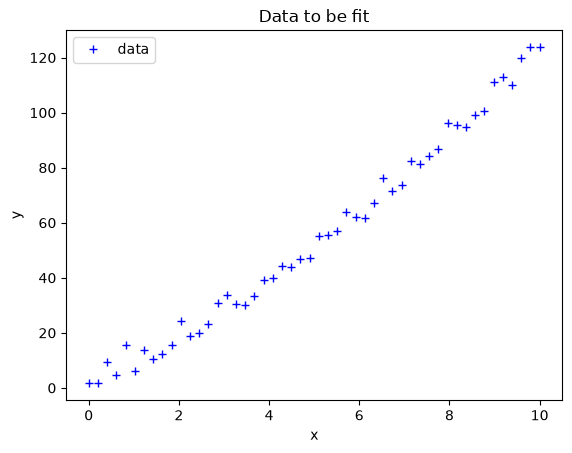

In [6]:
x = df["x"]
y = df["y"]

plt.plot(x, y, "b+", label = "data")
plt.title("Data to be fit")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()

plt.show()

In [7]:
def linear(x, m, b):
    return m * x + b 

In [8]:
popt, pcov = curve_fit(linear, x, y)

In [9]:
m_fit, b_fit = popt
print(f"line of best fit: {m_fit:.2f}x + {b_fit:.2f}")

line of best fit: 12.24x + -5.93


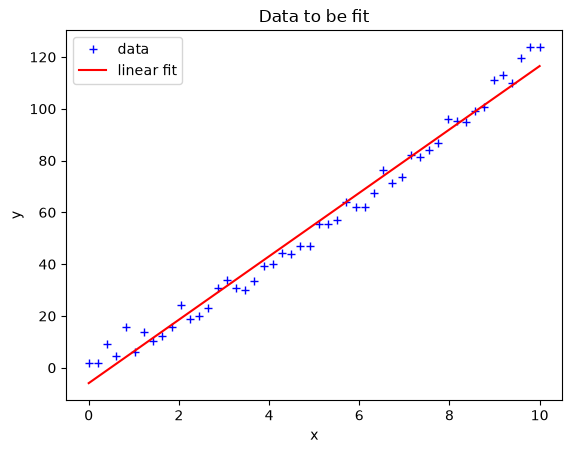

In [10]:
plt.plot(x, y, "b+", label = "data")
# y_fit = linear(x, m_fit, b_fit)
plt.plot(x, m_fit*x + b_fit, "r", label = "linear fit")
plt.title("Data to be fit")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()

plt.show()

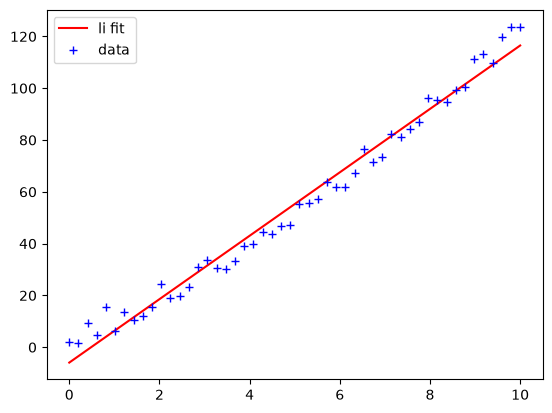

In [15]:
# Line of Best Fit
plt.plot(x, linear(x,*popt), color = "red", label = "li fit")
plt.plot(x, y, "b+", label = "data")
plt.legend()
plt.show()

In [17]:
perr = np.sqrt(np.diag(pcov))
m_err, b_err = perr

print(f"Slope : m = {m_fit:.2f} +- {m_err:.2f}")

Slope : m = 12.24 +- 0.24


In [20]:
residuals = y - linear(x, *popt)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2/dof

print(f"reduced chi sq = {chi2_reduced}")

reduced chi sq = 24.664948850009164
